### Design an IIR Notch Filter with Adjustable Bandwidth
    Design specifications:
    
    sampling frequency = 250 Hz
    duration = 4 seconds
    useful frequencies = 5, 12, 20 Hz
    main unwanted frequency = 50 Hz
    nearby interference = 48 and 52 Hz
    maximum passband error(0-20 Hz) = 1%
    maximum gain at 48 and 52 Hz = 0.45
    required gain at 50 Hz = 0
    filter type = second-order IIR notch

A zero at exactly 50 Hz doesn't guarantee sufficient attenuation at 48 and 52 Hz. That's why the notch width matters.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import freqz, lfilter

fs, duration = 250, 4
N = fs * duration
t = np.arange(N) / fs

#useful frequencies
clean = np.sin(2 * np.pi * 5 * t) + np.sin(2 * np.pi * 12 * t) + np.sin(2 * np.pi * 20 * t)
#unwanted interference
noise = 0.2 * np.sin(2 * np.pi * 48 * t) + 1.4 * np.sin(2 * np.pi * 50 * t) + 0.2 * np.sin(2 * np.pi * 52 * t)

x = clean + noise

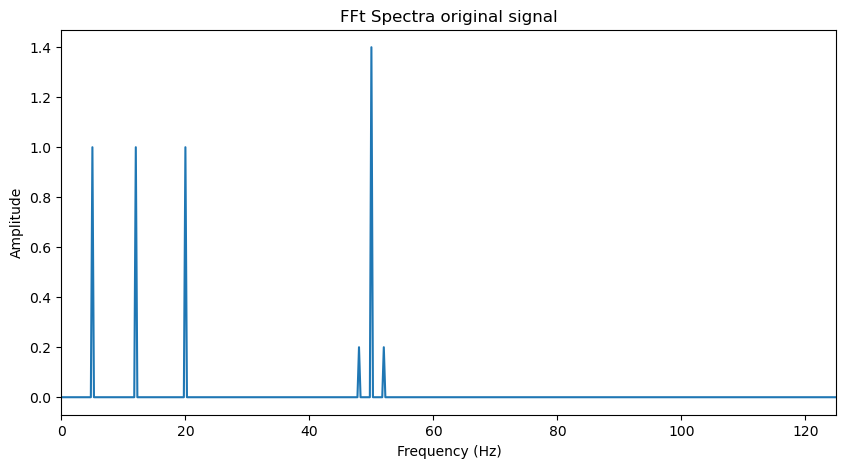

In [5]:
#FFT plot
freq_fft = np.fft.rfftfreq(N, d=1/fs)
amplitude_fft = np.abs(np.fft.rfft(x)) / N
amplitude_fft[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(freq_fft, amplitude_fft)
plt.xlim(0, 125)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("FFt Spectra original signal")
plt.show()

I place a pair of poles at the same angle as the 50 Hz zeros, but inside the unit circle.

The numerator creates the notch at 50 Hz, and the denominator helps control how narrow or broad the notch is.

A smaller rho generally produces a broader notch, removing more energy near 50 Hz, but can also affect useful frequencies.

A larger rho generally produces a narrower notch, preserving other frequencies better but potentially allowing interference at 48 and 52 Hz to pass through.

The job is to find a rho that meets both requirements: passband error at most 1%, and gain at 48 and 52 Hz at most 0.45.

rho = 0.75 : passband error = %2.958699026403744
gain at 48 Hz = 0.1797754575091219
gain at 52 Hz = 0.17984163776297898
-------
rho = 0.85 : passband error = %1.029856342224289
gain at 48 Hz = 0.2996953120912323
gain at 52 Hz = 0.29973089962182825
-------
rho = 0.9 : passband error = %0.4437055603705664
gain at 48 Hz = 0.4331737130517109
gain at 52 Hz = 0.4331953948183046
-------
rho = 0.95 : passband error = %0.10664072322676965
gain at 48 Hz = 0.7009114437140094
gain at 52 Hz = 0.7009197721434398
-------


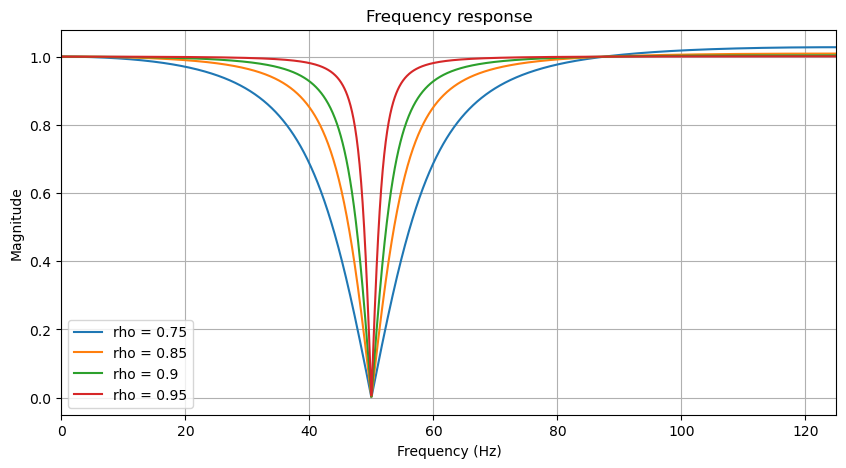

In [23]:
f0 = 50
theta0 = 2 * np.pi * f0 / fs
b_raw = np.array([1, -2 * np.cos(theta0), 1])
rhos = [0.75, 0.85, 0.90, 0.95]
plt.figure(figsize=(10, 5))
for rho in rhos:
    a = np.array([1, -2 * np.cos(theta0) * rho, rho ** 2])
    k = sum(a) / sum(b_raw)
    b_iir = k * b_raw
    f, H = freqz(b_iir, a, worN = 2048, fs=fs)
    magnitude = np.abs(H)
    plt.plot(f, magnitude, label = f"rho = {rho}")
    passband = f <= 20
    passband_error = np.max(np.abs(magnitude[passband] - 1)) * 100
    _, H48 = freqz(b, a, worN = [48], fs=fs)
    _, H52 = freqz(b, a, worN = [52], fs=fs)
    magnitude48 = np.abs(H48[0])
    magnitude52 = np.abs(H52[0])
    print(f"rho = {rho} : passband error = %{passband_error}")
    print(f"gain at 48 Hz = {magnitude48}")
    print(f"gain at 52 Hz = {magnitude52}")
    print("-------")

plt.xlim(0, 125)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Frequency response")
plt.grid(True)
plt.legend()
plt.show()

At rho=0.75 The notch is broad, but useful frequencies are attenuated too much.

At rho = 0.85 The passband improves considerably, but narrowly misses our 1% requirement.

At rho = 0.90, the filter preserves the useful frequencies within 1% and sufficiently attenuates both nearby interference frequencies.

At rho = 0.95 , the passband is even better, but the notch becomes too narrow to suppress 48 and 52 Hz sufficiently.

Therefore, Chosen Filter:
    f0 = 50 Hz and rho = 0.90

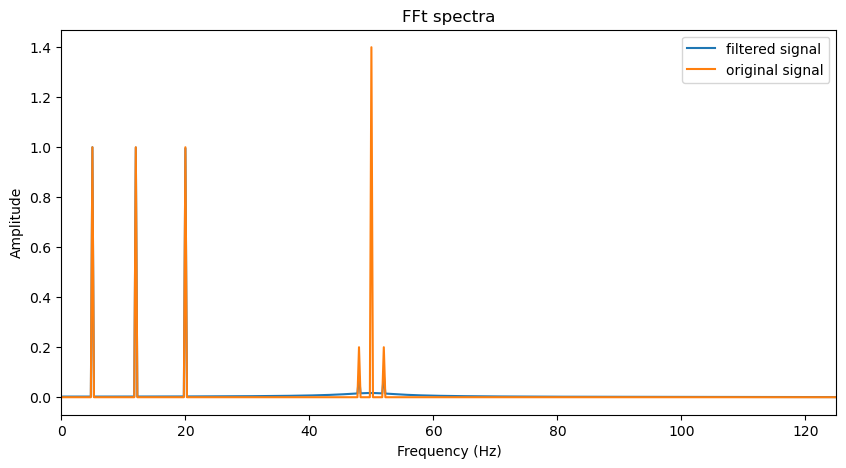

In [27]:
f0 = 50
theta0 = 2 * np.pi * f0 / fs
b = np.array([1, -2 * np.cos(theta0), 1])
rho = 0.90
a = np.array([1, -2 * np.cos(theta0) * rho, rho ** 2])
k = sum(a) / sum(b)
b_iir = k * b
iir_out = lfilter(b_iir, a, x)
iir_freq_fft = np.fft.rfftfreq(N, d=1/fs)
iir_amplitude_fft = np.abs(np.fft.rfft(iir_out)) / N
iir_amplitude_fft[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(iir_freq_fft, iir_amplitude_fft, label = "filtered signal")
plt.plot(freq_fft, amplitude_fft, label = "original signal")
plt.xlim(0, 125)
plt.legend()
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("FFt spectra")
plt.show()

### Examine group delay

In [36]:
from scipy.signal import group_delay

frequencies = [5, 12, 20]

f_delay, delay_samples = group_delay((b_iir, a), w=frequencies, fs=fs)
delay_ms = delay_samples / fs * 1000
for f, d in zip(f_delay, delay_ms):
    print(f"{f:.0f} Hz: {d:.3f} ms")

5 Hz: 0.622 ms
12 Hz: 0.706 ms
20 Hz: 0.940 ms


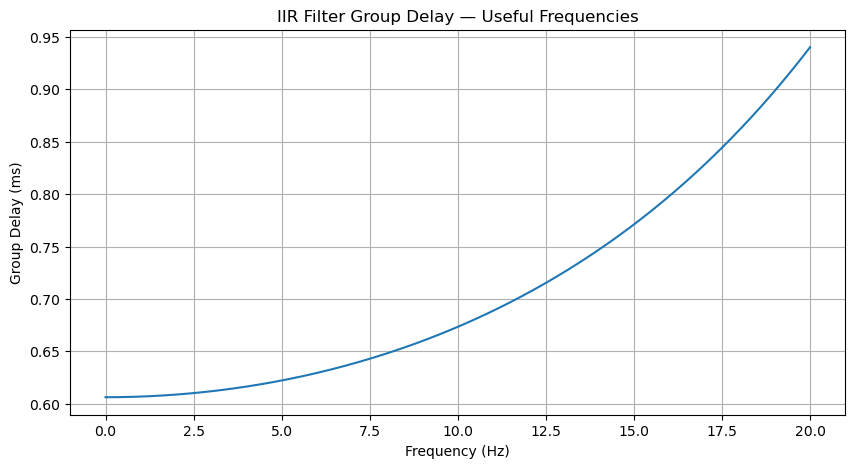

In [37]:
#plot group delay over useful passband
frequencies = np.linspace(0, 20, 300)

f_delay, delay_samples = group_delay(
    (b_iir, a),
    w=frequencies,
    fs=fs
)

delay_ms = delay_samples / fs * 1000

plt.figure(figsize=(10, 5))
plt.plot(f_delay, delay_ms)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Group Delay (ms)")
plt.title("IIR Filter Group Delay — Useful Frequencies")
plt.grid(True)
plt.show()

Group delay in useful band is About 0.6–0.94 ms at 5, 12 and 20 Hz